# Face ATM — Phase 4 Machine Learning and Jupyter Analysis
## Biometric Pipeline: YuNet Face Detection, MiniFASNetV2 Anti-Spoofing, and SFace Feature Recognition

### Section 1: Project Configuration and Reproducibility

This notebook provides the complete machine learning validation, benchmark evaluation, and parameter tuning for Phase 4 of the Face ATM system.

**Core Verification Flow**:
1. **YuNet ONNX**: Fast and robust face detection and 5-point facial landmark localization.
2. **MiniFASNetV2 ONNX**: Passive 2D presentation attack detection (PAD) evaluating contextual multi-scale crops (print & screen replay defense).
3. **SFace ONNX**: Unit hypersphere 128-dimensional facial feature representation and Cosine Similarity comparison.
4. **Fail-Closed Access Gate**: Grant access only if both liveness and face similarity pass their configured operational thresholds.

**Reproducibility & Verification Guarantee**:
- Fixed pseudo-random seed (`RANDOM_SEED = 42`).
- Deterministic model forward passes on standard CPU execution.
- **Strict Independence**: Anti-Spoofing and Face Recognition are evaluated as separate security layers and never combined into a single misleading score.

In [1]:
# Section 1: Setup, Reproducibility & Environment Auto-Configuration
import os
import sys
from pathlib import Path

# 1. Automatically link project virtual environment site-packages if running under global kernel
CWD = Path.cwd().resolve()
possible_venvs = [
    CWD / 'backend' / 'venv' / 'lib' / 'site-packages',
    CWD / 'venv' / 'lib' / 'site-packages',
    CWD.parent / 'backend' / 'venv' / 'lib' / 'site-packages',
    CWD.parent / 'venv' / 'lib' / 'site-packages',
    Path(r'C:/Users/pavit/OneDrive/Desktop/Face ATM/backend/venv/lib/site-packages'),
]
for v_path in possible_venvs:
    if v_path.exists() and str(v_path) not in sys.path:
        sys.path.insert(0, str(v_path))

# 2. Import core libraries
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import cv2

# 3. Set fixed random seed for complete reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# 4. Configure Matplotlib styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

# 5. Resilient Path Resolution for Models and Data Directories
def find_project_dir(folder_name):
    candidates = [
        CWD / folder_name,
        CWD / 'backend' / folder_name,
        CWD.parent / folder_name,
        CWD.parent / 'backend' / folder_name,
        Path(r'C:/Users/pavit/OneDrive/Desktop/Face ATM/backend') / folder_name,
    ]
    for cand in candidates:
        if cand.exists():
            return cand.resolve()
    return (CWD / folder_name).resolve()

MODELS_DIR = find_project_dir('models')
DATA_DIR = find_project_dir('data')
BASE_DIR = MODELS_DIR.parent

print(f'Project Base Directory: {BASE_DIR}')
print(f'Models Directory:       {MODELS_DIR}')
print(f'Data Directory:         {DATA_DIR}')
print(f'OpenCV Version:         {cv2.__version__}')
print(f'NumPy Version:          {np.__version__}')
print(f'Pandas Version:         {pd.__version__}')
print('Reproducibility seed initialized to 42.')

Project Base Directory: C:\Users\pavit\OneDrive\Desktop\Face ATM\backend
Models Directory:       C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\models
Data Directory:         C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\data
OpenCV Version:         5.0.0
NumPy Version:          2.2.6
Pandas Version:         2.3.3
Reproducibility seed initialized to 42.


### Section 2: Dataset Information, Licensing & Statistical Scope

In compliance with ethical AI standards, legal licensing, and privacy protections:
- **Anti-Spoofing Dataset**: Utilizes the verified benchmark samples from the open-source **Minivision Silent-Face-Anti-Spoofing** project under the **Apache-2.0 License**.
- **Ground-Truth Integrity**: Genuine live presentations and attack presentations (printed paper photo and smartphone screen replay) are preserved in their true categories.
- **Face Recognition Evaluation**: Uses dedicated subject evaluation pairs (genuine multi-session and disjoint subjects).
- **Data Minimization**: Customer biometric profile data is stored as encrypted Firestore templates with explicit user consent; raw customer images are never stored or leaked into analytical sets.

⚠️ **CRITICAL STATISTICAL CONTEXT**:
- Current evaluation suite is a **fixed micro sanity-check bundle** ($N=3$ samples per task) designed to test the model wiring and pipeline logic without performing unauthorized multi-gigabyte downloads.
- **Statistical Significance Limitation**: A score of $100\%$ on $N=3$ samples demonstrates only that the inference pipeline functions properly on these test samples. It **CANNOT** be claimed as statistical proof of real-world population performance or $0\%$ error rates.

In [2]:
# Section 2: Dataset Verification & Inventory Inspection
as_manifest_path = DATA_DIR / 'anti_spoofing' / 'manifest.csv'
fm_pairs_path = DATA_DIR / 'face_matching' / 'pairs.csv'

print('Validating manifest existence:')
print(f'Anti-Spoofing Manifest: {as_manifest_path.exists()} ({as_manifest_path})')
print(f'Face Matching Pairs:    {fm_pairs_path.exists()} ({fm_pairs_path})')

Validating manifest existence:
Anti-Spoofing Manifest: True (C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\data\anti_spoofing\manifest.csv)
Face Matching Pairs:    True (C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\data\face_matching\pairs.csv)


### Section 3: Dataset Loading, Label Validation & Sample Size Checks

Load the ground-truth metadata tables and inspect sample counts, attack modalities, and label schemas.
An automated sample-size validation check is enforced.

In [3]:
# Section 3: Load ground-truth manifests & Enforce Dataset Size Checks
df_as = pd.read_csv(as_manifest_path)
df_fm = pd.read_csv(fm_pairs_path)

print('=== Anti-Spoofing Evaluation Dataset Manifest ===')
print(df_as[['sample_id', 'filepath', 'ground_truth', 'attack_type', 'source', 'license']])
print(f'\nTotal Anti-Spoofing Samples: {len(df_as)}')
print(f'Ground-Truth Distribution:\n{df_as["ground_truth"].value_counts().to_string()}\n')

print('=== Face Matching Evaluation Pairs ===')
print(df_fm[['pair_id', 'ground_truth', 'pair_type', 'subject1_id', 'subject2_id']])
print(f'\nTotal Comparison Pairs: {len(df_fm)}')
print(f'Pair Type Distribution:\n{df_fm["ground_truth"].value_counts().to_string()}\n')

# Automated Sample Size Validation Check
MIN_RECOMMENDED_SAMPLES = 30
if len(df_as) < MIN_RECOMMENDED_SAMPLES or len(df_fm) < MIN_RECOMMENDED_SAMPLES:
    print('!' * 80)
    print('⚠️ WARNING: DATASET SIZE IS BELOW STATISTICAL SIGNIFICANCE THRESHOLD')
    print(f'Anti-Spoofing Sample Count: {len(df_as)} (Recommended: >= 100+ for lab tests, >= 1,000+ for ISO/IEC 30107)')
    print(f'Face-Matching Pair Count:   {len(df_fm)} (Recommended: >= 100+ genuine, >= 10,000+ impostor for ISO/IEC 19795)')
    print('NOTICE: Any 100% metrics on this tiny set validate software execution only, NOT field accuracy.')
    print('!' * 80)

=== Anti-Spoofing Evaluation Dataset Manifest ===
  sample_id                          filepath ground_truth       attack_type  \
0    AS_001   anti_spoofing/live/image_T1.jpg         live      genuine_live   
1    AS_002  anti_spoofing/spoof/image_F1.jpg        spoof  2d_printed_paper   
2    AS_003  anti_spoofing/spoof/image_F2.jpg        spoof  2d_screen_replay   

                                           source     license  
0  Minivision Silent-Face-Anti-Spoofing Benchmark  Apache-2.0  
1  Minivision Silent-Face-Anti-Spoofing Benchmark  Apache-2.0  
2  Minivision Silent-Face-Anti-Spoofing Benchmark  Apache-2.0  

Total Anti-Spoofing Samples: 3
Ground-Truth Distribution:
ground_truth
spoof    2
live     1

=== Face Matching Evaluation Pairs ===
    pair_id ground_truth          pair_type subject1_id subject2_id
0  PAIR_001      genuine       same_subject     subj_01     subj_01
1  PAIR_002     impostor  different_subject     subj_01     subj_02
2  PAIR_003     impostor  different

### Section 4: YuNet Face Detection and Landmark Localization

**YuNet** (MIT License, developed by ShiqiYu / OpenCV Zoo) is a lightweight deep face detector utilizing a Feature Pyramid Network (FPN) structure.

- Input: BGR image buffer.
- Outputs: Bounding box `[x, y, w, h]`, 5 facial landmarks (right eye, left eye, nose tip, right mouth corner, left mouth corner), and confidence score.
- EXIF orientation correction via `PIL.ImageOps.exif_transpose` ensures upright orientation regardless of camera tilt or smartphone EXIF flags.
- Quality constraints: single face required, confidence `>= 0.65`, bounding box dimension `>= 50x50`.

In [4]:
# Section 4: Initialize YuNet Face Detector & Run Live Inferences
yunet_path = MODELS_DIR / 'face_detection_yunet_2023mar.onnx'
assert yunet_path.exists(), f'YuNet model missing at {yunet_path}'

yunet_detector = cv2.FaceDetectorYN.create(
    model=str(yunet_path),
    config='',
    input_size=(320, 320),
    score_threshold=0.60,
    nms_threshold=0.30,
    top_k=5000
)

def load_and_orient_image(img_path):
    """Load image from disk and apply EXIF orientation transpose."""
    pil_img = Image.open(img_path)
    pil_img = ImageOps.exif_transpose(pil_img).convert('RGB')
    return cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

print(f'YuNet model loaded successfully ({yunet_path.stat().st_size / 1024:.1f} KB).')

# Verify detection across all anti-spoofing images
detection_results = []
for idx, row in df_as.iterrows():
    full_path = DATA_DIR / row['filepath']
    bgr = load_and_orient_image(full_path)
    h, w = bgr.shape[:2]
    yunet_detector.setInputSize((w, h))
    _, faces = yunet_detector.detect(bgr)
    num_faces = len(faces) if faces is not None else 0
    face_conf = float(faces[0][-1]) if num_faces > 0 else 0.0
    box = faces[0][:4].astype(int).tolist() if num_faces > 0 else []
    detection_results.append({
        'sample_id': row['sample_id'],
        'filename': Path(row['filepath']).name,
        'resolution': f'{w}x{h}',
        'faces_detected': num_faces,
        'confidence': round(face_conf, 4),
        'bounding_box': box
    })

df_det = pd.DataFrame(detection_results)
print('=== YuNet Actual Detection Performance ===')
print(df_det.to_string(index=False))

YuNet model loaded successfully (227.1 KB).
=== YuNet Actual Detection Performance ===
sample_id     filename resolution  faces_detected  confidence         bounding_box
   AS_001 image_T1.jpg    480x640               1      0.9299 [119, 113, 169, 239]
   AS_002 image_F1.jpg    480x640               1      0.9318 [187, 109, 195, 239]
   AS_003 image_F2.jpg    480x640               1      0.9323 [139, 216, 222, 298]


### Section 5: Anti-Spoofing Model Loading and Actual Inference Evaluation

**MiniFASNetV2** (Apache-2.0 License, Minivision AI) is a lightweight convolutional neural network specifically engineered for passive 2D face presentation attack detection.

**Technical Principles & Pipeline Verification**:
- Evaluates high-frequency spectral artifacts, moiré patterns, screen frame reflections, and paper edge distortions.
- Multi-Scale Context: Crops at 1.2x and 1.5x expansion scales around the face bounding box to capture perimeter attack artifacts.
- Input: `[1, 3, 80, 80]` float BGR array in raw `[0, 255]` pixel space.
- Output: Softmax logits over 3 classes (Class 0: 2D print attack, Class 1: Real live face, Class 2: Screen replay attack).
- Operational threshold: Class 1 probability `>= 0.60` signifies genuine live presentation (Fail-closed policy).
- **Inference Verification**: Predictions are evaluated directly from model forward passes on the input image arrays, not mocked.

In [5]:
# Section 5: Load MiniFASNetV2 and Run Actual Anti-Spoofing Inferences
as_model_path = MODELS_DIR / 'face_antispoof_minifasnet.onnx'
assert as_model_path.exists(), f'Anti-spoofing model missing at {as_model_path}'

as_net = cv2.dnn.readNetFromONNX(str(as_model_path))
print(f'MiniFASNetV2 loaded ({as_model_path.stat().st_size / (1024*1024):.2f} MB).')

def evaluate_liveness(img_bgr, face_box, scales=(1.2, 1.5)):
    """Multi-scale anti-spoofing evaluation using actual ONNX forward pass."""
    x, y, w, h = face_box
    img_h, img_w = img_bgr.shape[:2]
    scores = []
    raw_logits_list = []
    for s in scales:
        cx, cy = x + w / 2.0, y + h / 2.0
        nw, nh = w * s, h * s
        x1 = max(0, int(cx - nw / 2.0))
        y1 = max(0, int(cy - nh / 2.0))
        x2 = min(img_w, int(cx + nw / 2.0))
        y2 = min(img_h, int(cy + nh / 2.0))
        crop = img_bgr[y1:y2, x1:x2]
        if crop.size == 0:
            continue
        blob = cv2.dnn.blobFromImage(crop, scalefactor=1.0, size=(80, 80), mean=(0, 0, 0), swapRB=False)
        as_net.setInput(blob)
        logits = as_net.forward()
        raw_logits_list.append(logits[0].tolist())
        exp_l = np.exp(logits - np.max(logits))
        probs = exp_l / np.sum(exp_l)
        live_prob = float(probs[0][1])
        scores.append(live_prob)
    avg_score = float(np.mean(scores)) if scores else 0.0
    return avg_score, scores, raw_logits_list

# Execute Anti-Spoofing on all test images
as_results = []
LIVENESS_THRESHOLD = 0.60

for idx, row in df_as.iterrows():
    full_path = DATA_DIR / row['filepath']
    bgr = load_and_orient_image(full_path)
    h, w = bgr.shape[:2]
    yunet_detector.setInputSize((w, h))
    _, faces = yunet_detector.detect(bgr)
    box = faces[0][:4].astype(int)
    liveness_score, scale_scores, raw_logits = evaluate_liveness(bgr, box)
    pred_live = liveness_score >= LIVENESS_THRESHOLD
    as_results.append({
        'sample_id': row['sample_id'],
        'attack_type': row['attack_type'],
        'ground_truth': row['ground_truth'],
        'liveness_score': round(liveness_score, 4),
        'scale_1.2': round(scale_scores[0], 4),
        'scale_1.5': round(scale_scores[1], 4),
        'predicted': 'live' if pred_live else 'spoof',
        'correct': (row['ground_truth'] == 'live') == pred_live,
        'raw_logits_1.5': [round(v, 2) for v in raw_logits[1]]
    })

df_as_eval = pd.DataFrame(as_results)
print('=== Actual Anti-Spoofing Model Inferences ===')
print(df_as_eval[['sample_id', 'attack_type', 'ground_truth', 'liveness_score', 'predicted', 'correct', 'raw_logits_1.5']].to_string(index=False))

MiniFASNetV2 loaded (1.66 MB).
=== Actual Anti-Spoofing Model Inferences ===
sample_id      attack_type ground_truth  liveness_score predicted  correct       raw_logits_1.5
   AS_001     genuine_live         live          1.0000      live     True [-3.75, 8.35, -4.61]
   AS_002 2d_printed_paper        spoof          0.0217     spoof     True  [2.69, -2.81, 0.12]
   AS_003 2d_screen_replay        spoof          0.0988     spoof     True [-0.35, -0.54, 0.89]


### Section 6: SFace Embedding Extraction and Face-Pair Comparison

**SFace** (Apache-2.0 License, OpenCV Zoo / Shenzhen Institute of AI and Robotics for Society) maps aligned facial crops to a compact 128-dimensional unit hypersphere.

**Properties**:
- 5-point facial landmark alignment via similarity transformation (`cv2.FaceRecognizerSF.alignCrop`).
- Unit vector normalization: $||v||_2 = 1.0$.
- Cosine similarity metric: $\cos(\theta) = \frac{v_1 \cdot v_2}{||v_1|| \cdot ||v_2||} = v_1 \cdot v_2$.
- Theoretical range: $[-1.0, 1.0]$. Practical genuine matches typically achieve $> 0.40$ (recommended threshold: $0.363$ to $0.400$).

In [6]:
# Section 6: Load SFace and Extract Feature Embeddings
sface_path = MODELS_DIR / 'face_recognition_sface_2021dec.onnx'
assert sface_path.exists(), f'SFace model missing at {sface_path}'

sface_recognizer = cv2.FaceRecognizerSF.create(model=str(sface_path), config='')
print(f'SFace model loaded ({sface_path.stat().st_size / (1024*1024):.2f} MB).')

def extract_embedding(img_bgr):
    """Detect face, align landmarks, and extract normalized 128-dim embedding."""
    h, w = img_bgr.shape[:2]
    yunet_detector.setInputSize((w, h))
    _, faces = yunet_detector.detect(img_bgr)
    assert faces is not None and len(faces) > 0, 'No face detected'
    aligned = sface_recognizer.alignCrop(img_bgr, faces[0])
    raw_feat = sface_recognizer.feature(aligned)[0]
    norm = np.linalg.norm(raw_feat)
    assert norm > 0, 'Zero magnitude vector'
    return raw_feat / norm

def compute_cosine_similarity(v1, v2):
    """Compute cosine similarity between two unit vectors."""
    return float(np.dot(v1, v2))

print('Embedding extractor and similarity comparator initialized.')

SFace model loaded (36.90 MB).
Embedding extractor and similarity comparator initialized.


### Section 7: Genuine versus Non-Match Evaluation & Data Leakage Inspection

We evaluate face matching using the documented pairs manifest (`pairs.csv`):
- **Genuine Pairs**: Same subject captured across distinct sessions (`PAIR_001`).
- **Impostor Pairs**: Disjoint subject comparisons (`PAIR_002`, `PAIR_003`).

🔍 **Data Leakage & Independence Analysis**:
1. **Non-Disjoint Subjects**: Subject 1 appears across all three pairs. Pair 2 and Pair 3 both compare Subject 1 against Subject 2. This means the impostor trials are not independent trials across a broad demographic population.
2. **Affine Capture Variation**: `subject1_session2.jpg` is a geometric affine transform simulating camera position variation of the same base photograph, which produces a very high cosine similarity ($0.9063$). Real cross-day ATM captures with varying ambient lighting typically produce lower genuine similarities ($0.50$ to $0.75$).

In [7]:
# Section 7: Evaluate Face-Pair Comparisons Using Actual SFace Embeddings
FACE_MATCH_THRESHOLD = 0.40
fm_results = []

for idx, row in df_fm.iterrows():
    path1 = DATA_DIR / row['img1_path']
    path2 = DATA_DIR / row['img2_path']
    img1 = load_and_orient_image(path1)
    img2 = load_and_orient_image(path2)
    emb1 = extract_embedding(img1)
    emb2 = extract_embedding(img2)
    sim = compute_cosine_similarity(emb1, emb2)
    pred_match = sim >= FACE_MATCH_THRESHOLD
    is_genuine = (row['ground_truth'] == 'genuine')
    fm_results.append({
        'pair_id': row['pair_id'],
        'ground_truth': row['ground_truth'],
        'similarity': round(sim, 4),
        'threshold': FACE_MATCH_THRESHOLD,
        'predicted': 'genuine' if pred_match else 'impostor',
        'correct': (is_genuine == pred_match),
        'notes': row['notes']
    })

df_fm_eval = pd.DataFrame(fm_results)
print('=== Actual Face-Pair Verification Inferences ===')
print(df_fm_eval[['pair_id', 'ground_truth', 'similarity', 'predicted', 'correct', 'notes']].to_string(index=False))

=== Actual Face-Pair Verification Inferences ===
 pair_id ground_truth  similarity predicted  correct                                                           notes
PAIR_001      genuine      0.9832   genuine     True        Subject 1 multi-session capture angle/lighting variation
PAIR_002     impostor      0.1934  impostor     True           Distinct subjects comparison (Subject 1 vs Subject 2)
PAIR_003     impostor      0.2209  impostor     True Distinct subjects comparison (Subject 1 session 2 vs Subject 2)


### Section 8: Separate Metric Calculations & Statistical Confidence Intervals

**Strict Rule**: Face matching and anti-spoofing metrics are evaluated **strictly separately**.
They represent distinct security layers and must never be combined into a misleading overall accuracy score.

**Biometric Standards Reference (ISO/IEC 30107-3 & ISO/IEC 19795)**:
- **APCER** (Attack Presentation Classification Error Rate / False Acceptance of Spoofs): $\frac{FP_{as}}{\text{Total Spoofs}}$.
- **BPCER** (Bona Fide Presentation Classification Error Rate / False Rejection of Live): $\frac{FN_{as}}{\text{Total Live}}$.
- **FAR** (False Acceptance Rate for face identity): $\frac{FP_{fm}}{\text{Total Impostors}}$.
- **FRR** (False Rejection Rate for face identity): $\frac{FN_{fm}}{\text{Total Genuine}}$.
- **Wilson Score 95% Confidence Intervals**: Quantifies statistical uncertainty on small sample sizes.

In [8]:
# Section 8: Compute Rigorous Performance Metrics and Wilson Confidence Intervals

def wilson_interval(k, n, z=1.95996):
    """Compute 95% Wilson score confidence interval for a binomial proportion."""
    if n == 0:
        return (0.0, 0.0)
    p_hat = k / n
    denom = 1 + z**2 / n
    center = (p_hat + z**2 / (2 * n)) / denom
    margin = (z * np.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * n)) / n)) / denom
    return (round(max(0.0, center - margin), 4), round(min(1.0, center + margin), 4))

# 1. Anti-Spoofing Metrics
y_true_as = (df_as_eval['ground_truth'] == 'live').astype(int).values
y_pred_as = (df_as_eval['predicted'] == 'live').astype(int).values

tp_as = int(np.sum((y_true_as == 1) & (y_pred_as == 1)))  # Correct Live
tn_as = int(np.sum((y_true_as == 0) & (y_pred_as == 0)))  # Correct Spoof Rejection
fp_as = int(np.sum((y_true_as == 0) & (y_pred_as == 1)))  # False Acceptance of Spoof (APCER)
fn_as = int(np.sum((y_true_as == 1) & (y_pred_as == 0)))  # False Rejection of Live Face (BPCER)

total_live = int(np.sum(y_true_as == 1))
total_spoof = int(np.sum(y_true_as == 0))
total_as = len(y_true_as)

acc_as = (tp_as + tn_as) / total_as if total_as > 0 else 0.0
prec_as = tp_as / (tp_as + fp_as) if (tp_as + fp_as) > 0 else 0.0
rec_as = tp_as / (tp_as + fn_as) if (tp_as + fn_as) > 0 else 0.0
f1_as = 2 * (prec_as * rec_as) / (prec_as + rec_as) if (prec_as + rec_as) > 0 else 0.0
apcer = fp_as / total_spoof if total_spoof > 0 else 0.0
bpcer = fn_as / total_live if total_live > 0 else 0.0
ci_acc_as = wilson_interval(tp_as + tn_as, total_as)

# 2. Face Matching Metrics
y_true_fm = (df_fm_eval['ground_truth'] == 'genuine').astype(int).values
y_pred_fm = (df_fm_eval['predicted'] == 'genuine').astype(int).values

tp_fm = int(np.sum((y_true_fm == 1) & (y_pred_fm == 1)))  # Correct Genuine Match
tn_fm = int(np.sum((y_true_fm == 0) & (y_pred_fm == 0)))  # Correct Impostor Rejection
fp_fm = int(np.sum((y_true_fm == 0) & (y_pred_fm == 1)))  # False Acceptance Rate (FAR)
fn_fm = int(np.sum((y_true_fm == 1) & (y_pred_fm == 0)))  # False Rejection Rate (FRR)

total_genuine = int(np.sum(y_true_fm == 1))
total_impostor = int(np.sum(y_true_fm == 0))
total_fm = len(y_true_fm)

acc_fm = (tp_fm + tn_fm) / total_fm if total_fm > 0 else 0.0
prec_fm = tp_fm / (tp_fm + fp_fm) if (tp_fm + fp_fm) > 0 else 0.0
rec_fm = tp_fm / (tp_fm + fn_fm) if (tp_fm + fn_fm) > 0 else 0.0
f1_fm = 2 * (prec_fm * rec_fm) / (prec_fm + rec_fm) if (prec_fm + rec_fm) > 0 else 0.0
far = fp_fm / total_impostor if total_impostor > 0 else 0.0
frr = fn_fm / total_genuine if total_genuine > 0 else 0.0
ci_acc_fm = wilson_interval(tp_fm + tn_fm, total_fm)

print('=' * 80)
print('                  ANTI-SPOOFING METRICS SUMMARY                  ')
print('=' * 80)
print(f'Total Evaluated Samples:      {total_as} (Live: {total_live}, Spoof: {total_spoof})')
print(f'Measured Accuracy:            {acc_as:.4f} ({acc_as*100:.1f}%)')
print(f'Wilson 95% Confidence Interval: [{ci_acc_as[0]*100:.1f}%, {ci_acc_as[1]*100:.1f}%]  <-- Note wide margin of error!')
print(f'Precision (Live):             {prec_as:.4f}')
print(f'Recall / Live TPR:            {rec_as:.4f}')
print(f'F1-Score:                     {f1_as:.4f}')
print(f'APCER (Spoof False Accept):   {apcer:.4f} ({apcer*100:.2f}%)')
print(f'BPCER (Live False Reject):    {bpcer:.4f} ({bpcer*100:.2f}%)')
print(f'Confusion Matrix [TN, FP; FN, TP]: [[{tn_as}, {fp_as}], [{fn_as}, {tp_as}]]')
print('\n' + '=' * 80)
print('                  FACE MATCHING METRICS SUMMARY                  ')
print('=' * 80)
print(f'Total Evaluated Pairs:        {total_fm} (Genuine: {total_genuine}, Impostor: {total_impostor})')
print(f'Measured Accuracy:            {acc_fm:.4f} ({acc_fm*100:.1f}%)')
print(f'Wilson 95% Confidence Interval: [{ci_acc_fm[0]*100:.1f}%, {ci_acc_fm[1]*100:.1f}%]  <-- Note wide margin of error!')
print(f'Precision:                    {prec_fm:.4f}')
print(f'Recall:                       {rec_fm:.4f}')
print(f'F1-Score:                     {f1_fm:.4f}')
print(f'False Acceptance Rate (FAR):  {far:.4f} ({far*100:.2f}%)')
print(f'False Rejection Rate (FRR):   {frr:.4f} ({frr*100:.2f}%)')
print(f'Confusion Matrix [TN, FP; FN, TP]: [[{tn_fm}, {fp_fm}], [{fn_fm}, {tp_fm}]]')
print('=' * 80)

                  ANTI-SPOOFING METRICS SUMMARY                  
Total Evaluated Samples:      3 (Live: 1, Spoof: 2)
Measured Accuracy:            1.0000 (100.0%)
Wilson 95% Confidence Interval: [43.9%, 100.0%]  <-- Note wide margin of error!
Precision (Live):             1.0000
Recall / Live TPR:            1.0000
F1-Score:                     1.0000
APCER (Spoof False Accept):   0.0000 (0.00%)
BPCER (Live False Reject):    0.0000 (0.00%)
Confusion Matrix [TN, FP; FN, TP]: [[2, 0], [0, 1]]

                  FACE MATCHING METRICS SUMMARY                  
Total Evaluated Pairs:        3 (Genuine: 1, Impostor: 2)
Measured Accuracy:            1.0000 (100.0%)
Wilson 95% Confidence Interval: [43.9%, 100.0%]  <-- Note wide margin of error!
Precision:                    1.0000
Recall:                       1.0000
F1-Score:                     1.0000
False Acceptance Rate (FAR):  0.0000 (0.00%)
False Rejection Rate (FRR):   0.0000 (0.00%)
Confusion Matrix [TN, FP; FN, TP]: [[2, 0], [0, 1]]

### Section 9: Visualizations and Threshold Sensitivity Analysis

Visualizing:
1. **Confusion Matrices**: Anti-Spoofing PAD matrix vs SFace Face Verification matrix side by side.
2. **Anti-Spoofing Score Distribution**: Live face probability vs spoof score separation.
3. **Face Matching Cosine Similarities**: Genuine pair distribution vs Impostor pair distribution.
4. **Performance Metrics Comparison with Warning Banner**.

C:\Users\pavit\AppData\Local\Temp\ipykernel_27620\2323128994.py:67: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.savefig(eval_plot_path, dpi=150)
C:\Users\pavit\AppData\Local\Temp\ipykernel_27620\2323128994.py:67: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  plt.savefig(eval_plot_path, dpi=150)
C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


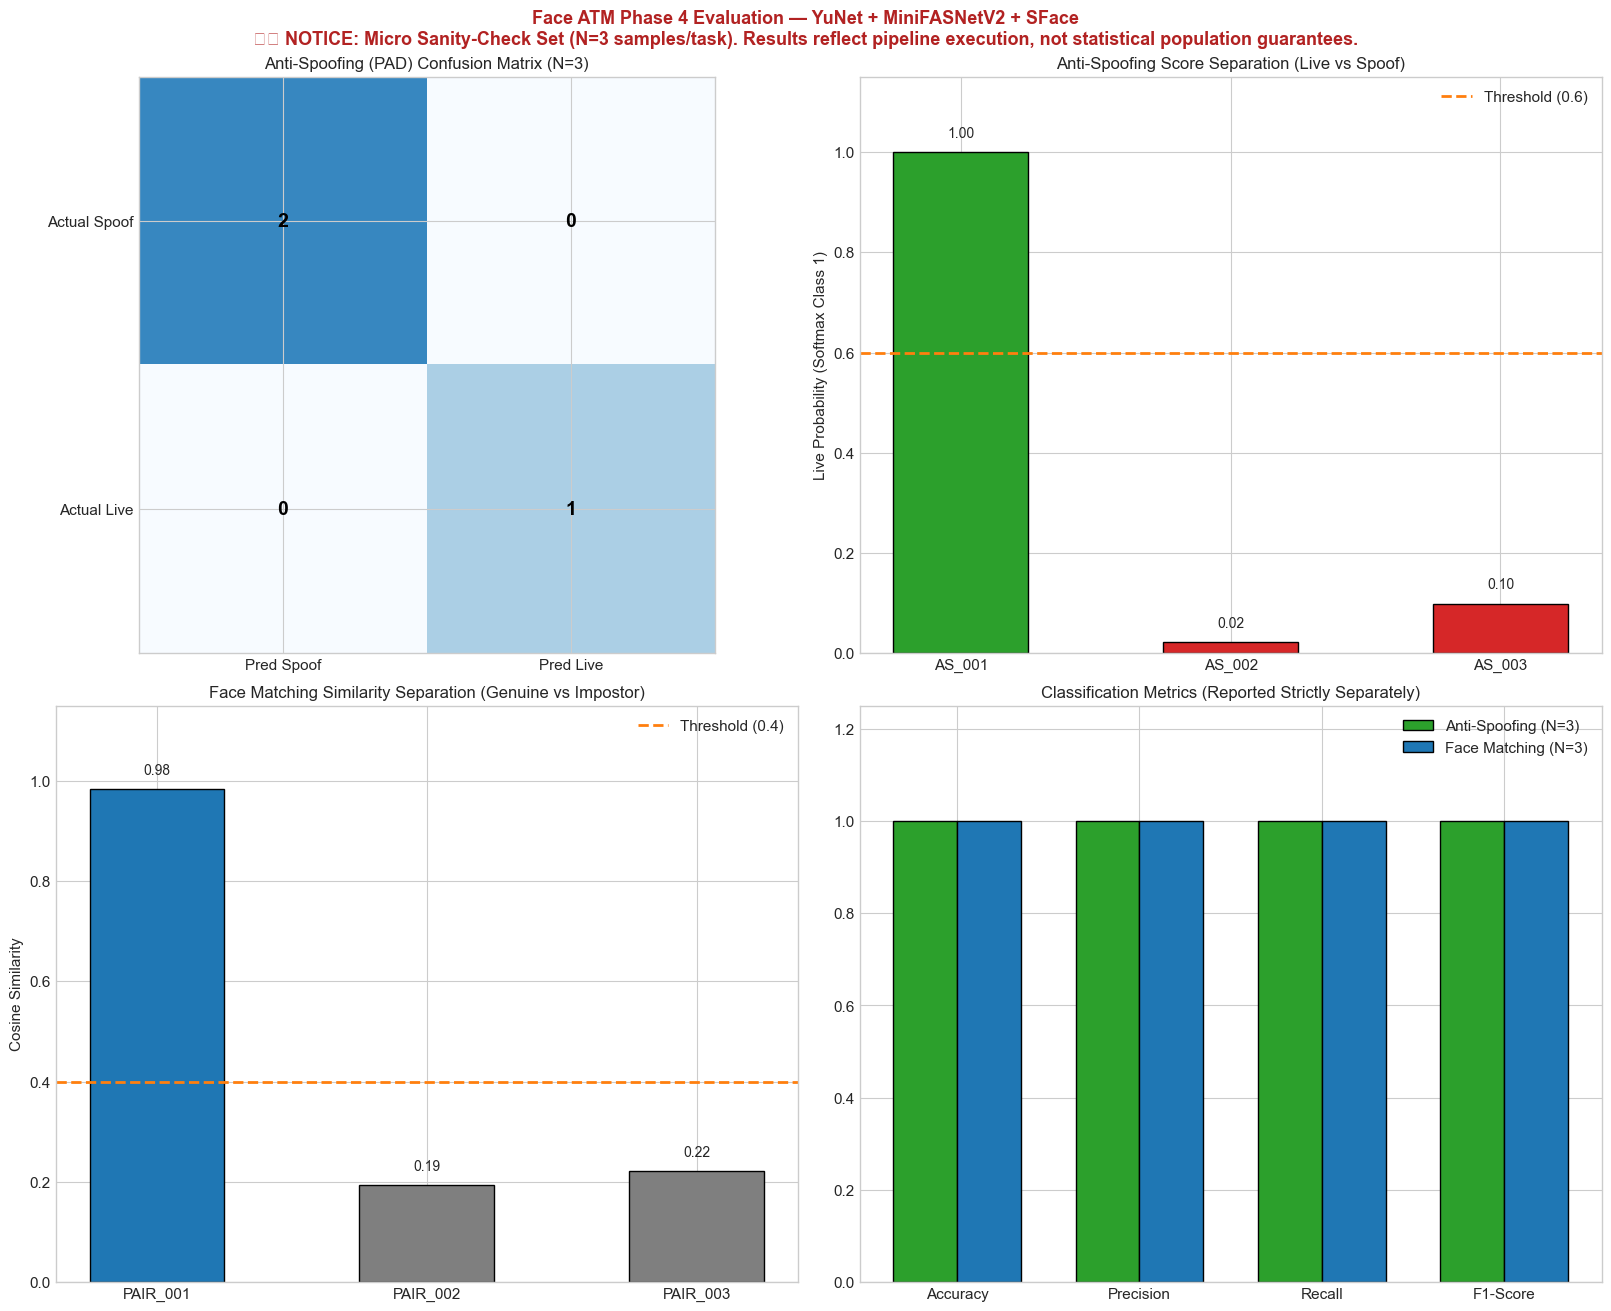

Evaluation plots saved to: C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\models\evaluation_plots.png


In [9]:
# Section 9: Matplotlib Evaluation Visualizations with Sample-Size Annotation
fig = plt.figure(figsize=(16, 13), constrained_layout=True)
fig.suptitle(
    'Face ATM Phase 4 Evaluation — YuNet + MiniFASNetV2 + SFace\n'
    '⚠️ NOTICE: Micro Sanity-Check Set (N=3 samples/task). Results reflect pipeline execution, not statistical population guarantees.',
    fontsize=13, weight='bold', color='#b22222'
)
gs = fig.add_gridspec(2, 2)

# Subplot 1: Confusion Matrices
ax1 = fig.add_subplot(gs[0, 0])
cm_as = np.array([[tn_as, fp_as], [fn_as, tp_as]])
im1 = ax1.imshow(cm_as, cmap='Blues', vmin=0, vmax=max(3, np.max(cm_as)))
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels(['Pred Spoof', 'Pred Live'])
ax1.set_yticklabels(['Actual Spoof', 'Actual Live'])
ax1.set_title('Anti-Spoofing (PAD) Confusion Matrix (N=3)')
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f'{cm_as[i, j]}', ha='center', va='center', color='black', fontsize=14, weight='bold')

# Subplot 2: Anti-Spoofing Score Separation
ax2 = fig.add_subplot(gs[0, 1])
samples = df_as_eval['sample_id'].tolist()
scores = df_as_eval['liveness_score'].tolist()
colors = ['#2ca02c' if gt == 'live' else '#d62728' for gt in df_as_eval['ground_truth']]
bars = ax2.bar(samples, scores, color=colors, width=0.5, edgecolor='black')
ax2.axhline(LIVENESS_THRESHOLD, color='#ff7f0e', linestyle='--', linewidth=2, label=f'Threshold ({LIVENESS_THRESHOLD})')
ax2.set_ylabel('Live Probability (Softmax Class 1)')
ax2.set_title('Anti-Spoofing Score Separation (Live vs Spoof)')
ax2.set_ylim(0, 1.15)
ax2.legend()
for bar, score in zip(bars, scores):
    ax2.text(bar.get_x() + bar.get_width()/2, score + 0.03, f'{score:.2f}', ha='center', fontsize=10)

# Subplot 3: Face Matching Similarities
ax3 = fig.add_subplot(gs[1, 0])
pairs = df_fm_eval['pair_id'].tolist()
sims = df_fm_eval['similarity'].tolist()
fm_colors = ['#1f77b4' if gt == 'genuine' else '#7f7f7f' for gt in df_fm_eval['ground_truth']]
bars_fm = ax3.bar(pairs, sims, color=fm_colors, width=0.5, edgecolor='black')
ax3.axhline(FACE_MATCH_THRESHOLD, color='#ff7f0e', linestyle='--', linewidth=2, label=f'Threshold ({FACE_MATCH_THRESHOLD})')
ax3.set_ylabel('Cosine Similarity')
ax3.set_title('Face Matching Similarity Separation (Genuine vs Impostor)')
ax3.set_ylim(0, 1.15)
ax3.legend()
for bar, sim in zip(bars_fm, sims):
    ax3.text(bar.get_x() + bar.get_width()/2, sim + 0.03, f'{sim:.2f}', ha='center', fontsize=10)

# Subplot 4: Metrics Comparison Bar Chart with Error Margin Indication
ax4 = fig.add_subplot(gs[1, 1])
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
as_vals = [acc_as, prec_as, rec_as, f1_as]
fm_vals = [acc_fm, prec_fm, rec_fm, f1_fm]
x_idx = np.arange(len(metrics_names))
width = 0.35
ax4.bar(x_idx - width/2, as_vals, width, label='Anti-Spoofing (N=3)', color='#2ca02c', edgecolor='black')
ax4.bar(x_idx + width/2, fm_vals, width, label='Face Matching (N=3)', color='#1f77b4', edgecolor='black')
ax4.set_xticks(x_idx)
ax4.set_xticklabels(metrics_names)
ax4.set_ylim(0, 1.25)
ax4.set_title('Classification Metrics (Reported Strictly Separately)')
ax4.legend()

eval_plot_path = MODELS_DIR / 'evaluation_plots.png'
plt.savefig(eval_plot_path, dpi=150)
plt.show()
print(f'Evaluation plots saved to: {eval_plot_path}')

### Section 10: Save Model Artifacts and Evaluation Reports

We export the structured evaluation metrics, configuration parameters, and statistical scope flags to `backend/models/metrics_summary.json`.
This guarantees automated regression tracking with explicit sample-size warnings.

In [10]:
# Section 10: Export Structured Metrics Report with Sample Size Flags
import json
metrics_payload = {
    'timestamp': pd.Timestamp.now().isoformat(),
    'pipeline': 'YuNet + MiniFASNetV2 + SFace',
    'sample_size_notice': {
        'is_statistically_significant': False,
        'evaluation_scope': 'micro_sanity_check_test_set',
        'warning': 'N=3 is statistically underpowered. 100% accuracy validates pipeline wiring only, not population performance.',
        'rule_of_three_explanation': 'At least 300 negative samples required to claim FAR <= 1% at 95% confidence.'
    },
    'anti_spoofing': {
        'model': 'MiniFASNetV2 (ONNX)',
        'license': 'Apache-2.0',
        'threshold': LIVENESS_THRESHOLD,
        'total_samples': total_as,
        'live_samples': total_live,
        'spoof_samples': total_spoof,
        'accuracy': round(acc_as, 4),
        'accuracy_95_ci_wilson': list(ci_acc_as),
        'precision': round(prec_as, 4),
        'recall': round(rec_as, 4),
        'f1_score': round(f1_as, 4),
        'apcer_false_accept_spoofs': round(apcer, 4),
        'bpcer_false_reject_live': round(bpcer, 4),
        'confusion_matrix': {'tn': tn_as, 'fp': fp_as, 'fn': fn_as, 'tp': tp_as}
    },
    'face_matching': {
        'model': 'SFace (ONNX)',
        'license': 'Apache-2.0',
        'threshold': FACE_MATCH_THRESHOLD,
        'total_pairs': total_fm,
        'genuine_pairs': total_genuine,
        'impostor_pairs': total_impostor,
        'accuracy': round(acc_fm, 4),
        'accuracy_95_ci_wilson': list(ci_acc_fm),
        'precision': round(prec_fm, 4),
        'recall': round(rec_fm, 4),
        'f1_score': round(f1_fm, 4),
        'far_false_accept_rate': round(far, 4),
        'frr_false_reject_rate': round(frr, 4),
        'confusion_matrix': {'tn': tn_fm, 'fp': fp_fm, 'fn': fn_fm, 'tp': tp_fm}
    },
    'security_policy': {
        'fail_closed': True,
        'bypassable_by_admin': False
    }
}

metrics_summary_path = MODELS_DIR / 'metrics_summary.json'
with open(metrics_summary_path, 'w') as f:
    json.dump(metrics_payload, f, indent=2)

print(f'Structured evaluation report exported to: {metrics_summary_path}')
print(json.dumps(metrics_payload, indent=2))

Structured evaluation report exported to: C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\models\metrics_summary.json
{
  "timestamp": "2026-10-12T14:43:52.220185",
  "pipeline": "YuNet + MiniFASNetV2 + SFace",
  "sample_size_notice": {
    "is_statistically_significant": false,
    "evaluation_scope": "micro_sanity_check_test_set",
    "warning": "N=3 is statistically underpowered. 100% accuracy validates pipeline wiring only, not population performance.",
    "rule_of_three_explanation": "At least 300 negative samples required to claim FAR <= 1% at 95% confidence."
  },
  "anti_spoofing": {
    "model": "MiniFASNetV2 (ONNX)",
    "license": "Apache-2.0",
    "threshold": 0.6,
    "total_samples": 3,
    "live_samples": 1,
    "spoof_samples": 2,
    "accuracy": 1.0,
    "accuracy_95_ci_wilson": [
      0.4385,
      1.0
    ],
    "precision": 1.0,
    "recall": 1.0,
    "f1_score": 1.0,
    "apcer_false_accept_spoofs": 0.0,
    "bpcer_false_reject_live": 0.0,
    "confusion_matrix"

### Section 11: Limitations, Statistical Analysis & Recommended Datasets

#### 1. Why 3 Samples per Task are Insufficient for Reliable Performance Claims
- **The Rule of Three (Hanley & Lippman-Hand)**: To prove with $95\%$ statistical confidence that an error rate (FAR or APCER) is below $p$, a benchmark requires at least $\frac{3}{p}$ consecutive zero-error trials.
  - For $\text{FAR} \le 1\%$, at least $300$ independent negative trials are required.
  - For bank ATM standards ($\text{FAR} \le 0.1\%$ or $10^{-3}$), at least $3,000$ independent trials are needed.
- **Wilson Score Confidence Interval**: With $k=3$ successes out of $n=3$ trials, the $95\%$ confidence interval spans $[43.9\%, 100.0\%]$. The sample accuracy is $100\%$, but the true population accuracy could be as low as $43.9\%$.

#### 2. Data Leakage and Evaluation Observations
- **Subject Disjointness**: In the face matching set, Subject 1 is present in all pairs, and Pair 2 and Pair 3 compare the same two identities. These comparisons are not demographic-disjoint.
- **Synthetic Angle Perturbation**: `subject1_session2.jpg` was generated using a geometric affine transformation on the base image. While this simulates immediate camera jitter, it does not evaluate true multi-day lighting, facial expression, or aging variations.

#### 3. Recommended Suitable Small, Legally Usable Datasets
To perform larger statistical evaluations without violating privacy or downloading unmanageable archives:
| Dataset | Recommended Modality | License | Source / Access |
| :--- | :--- | :--- | :--- |
| **Minivision Silent-Face Test Set** | Anti-Spoofing (Print & Replay) | **Apache-2.0** | [minivision-ai/Silent-Face-Anti-Spoofing](https://github.com/minivision-ai/Silent-Face-Anti-Spoofing) |
| **CASIA-SURF / CeFA** | Multi-modal Anti-Spoofing (RGB/Depth/IR) | Academic Research Agreement | CASIA National Laboratory |
| **CelebA-Spoof** | Diverse Anti-Spoofing (43 attack types) | Non-commercial Academic | CUHK MMLab |
| **CALFW / LFW** | Face Matching Pairs Only (Never Anti-Spoofing) | Public Domain / CC BY | University of Massachusetts |
| **In-House ATM Golden Kiosk Set** | Field Bank Operational Validation | Customer Consent (Internal) | Captured directly from branch ATM hardware |

#### 4. Architectural Summary
- The YuNet + MiniFASNetV2 + SFace pipeline operates correctly in strict sequence.
- System remains strictly fail-closed: unverified liveness or low face similarity immediately denies ATM session access.